# 1. Load data


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv(r'C:\Project\churn_stats\Churn_Modelling.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# 2. Process data


In [32]:
df = df.drop(columns = ['RowNumber'])
df = df.rename(columns={
    "CustomerId": "customer_id",
    "Surname": "surname",
    "CreditScore": "credit_score",
    "Geography": "geography",
    "Gender": "gender",
    "Age": "age",
    "Tenure": "tenure",
    "Balance": "balance",
    "NumOfProducts": "num_of_products",
    "HasCrCard": "has_credit_card",
    "IsActiveMember": "is_active_member",
    "EstimatedSalary": "estimated_salary",
    "Exited": "exited",
})
df.head()

,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_credit_card,is_active_member,estimated_salary,exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [33]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   surname           10000 non-null  object 
 2   credit_score      10000 non-null  int64  
 3   geography         10000 non-null  object 
 4   gender            10000 non-null  object 
 5   age               10000 non-null  int64  
 6   tenure            10000 non-null  int64  
 7   balance           10000 non-null  float64
 8   num_of_products   10000 non-null  int64  
 9   has_credit_card   10000 non-null  int64  
 10  is_active_member  10000 non-null  int64  
 11  estimated_salary  10000 non-null  float64
 12  exited            10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1015.8+ KB
None


In [34]:
df[['customer_id', 'surname','gender','geography']] = df[['customer_id', 'surname','gender','geography']].astype('string')
df['geography'] = df['geography'].astype('category')
df['gender'] = df['gender'].astype('category')
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customer_id       10000 non-null  string  
 1   surname           10000 non-null  string  
 2   credit_score      10000 non-null  int64   
 3   geography         10000 non-null  category
 4   gender            10000 non-null  category
 5   age               10000 non-null  int64   
 6   tenure            10000 non-null  int64   
 7   balance           10000 non-null  float64 
 8   num_of_products   10000 non-null  int64   
 9   has_credit_card   10000 non-null  int64   
 10  is_active_member  10000 non-null  int64   
 11  estimated_salary  10000 non-null  float64 
 12  exited            10000 non-null  int64   
dtypes: category(2), float64(2), int64(7), string(2)
memory usage: 879.3 KB
None


# 3. Exploratory Data Analysis


In [35]:
print("Null:", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df.describe()

Null: customer_id         0
surname             0
credit_score        0
geography           0
gender              0
age                 0
tenure              0
balance             0
num_of_products     0
has_credit_card     0
is_active_member    0
estimated_salary    0
exited              0
dtype: int64
Duplicates: 0


,credit_score,age,tenure,balance,num_of_products,has_credit_card,is_active_member,estimated_salary,exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


## 3.1. Customers Churn Rate

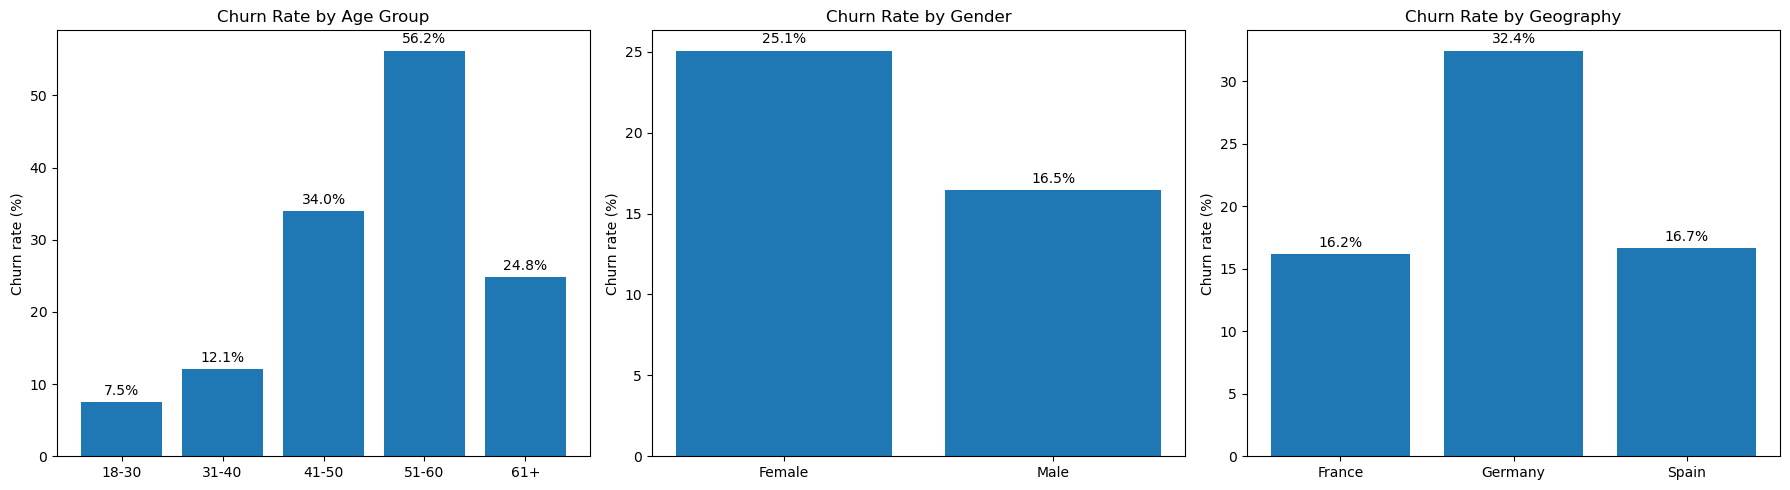

In [36]:
bins = [17,30,40,50,60,100]
labels = ['18-30','31-40','41-50','51-60','61+']
df['age_group'] = pd.cut(df['age'],bins = bins, labels = labels)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

rate = df.groupby('age_group', observed=True)['exited'].mean() * 100
bars = axes[0].bar(rate.index.astype(str), rate.values)
axes[0].bar_label(bars, fmt='%.1f%%', padding=3)
axes[0].set_title('Churn Rate by Age Group')
axes[0].set_ylabel('Churn rate (%)')

rate = df.groupby('gender', observed=True)['exited'].mean() * 100
bars = axes[1].bar(rate.index, rate.values)
axes[1].bar_label(bars, fmt='%.1f%%', padding=3)
axes[1].set_title('Churn Rate by Gender')
axes[1].set_ylabel('Churn rate (%)')

rate = df.groupby('geography', observed=True)['exited'].mean() * 100
bars = axes[2].bar(rate.index, rate.values)
axes[2].bar_label(bars, fmt='%.1f%%', padding=3)
axes[2].set_title('Churn Rate by Geography')
axes[2].set_ylabel('Churn rate (%)')

plt.tight_layout()
plt.show()

In [37]:
(df.groupby(['geography', 'gender', 'age_group'], observed=True)['exited']
   .agg(rate='mean', n='size')
   .sort_values('rate', ascending=False)
   .head(10))

rate    n
geography gender age_group               
Germany   Female 51-60      0.736434  129
          Male   51-60      0.649123  114
France    Female 51-60      0.643275  171
Spain     Female 51-60      0.549451   91
Germany   Female 41-50      0.524242  330
                 61+        0.509434   53
          Male   41-50      0.454023  348
France    Male   51-60      0.423469  196
Spain     Male   51-60      0.375000   96
          Female 41-50      0.335793  271

**Key Findings**

- The highest observed churn rates are concentrated among customers **51-60**, **female**, and customers in **Germany**
- The combination **female**, **51-60**, and **Germany** has the highest observed churn rate in this sample (**73.6%**, `n = 129`), compared with the overall churn rate of approximately **20.4%**
- All 10 highest-churn combinations include customers **41+**

## 3.2. Pairplot

In [ ]:
sns.pairplot(df, vars=['age', 'balance', 'credit_score','estimated_salary'], hue='exited')

**Distributional Findings**

- **Age**: Churned customers are concentrated at older ages than retained customers. This suggests age may be useful for describing churn patterns; the adjusted **nonlinear** relationship is examined in the logistic model
- **Balance** also exhibits a **noticeable relationship** with churn, suggesting that customers' account balances may be associated with their likelihood of leaving
- **Credit score** and **estimated salary**: Their distributions overlap substantially between churned and retained customers, suggesting **limited separation** by these variables alone

**Scatterplot Findings**

- **Age** shows the clearest visible pattern with churn; the remaining variables show weaker visual separation

## 3.3. Logistic Regression Plots

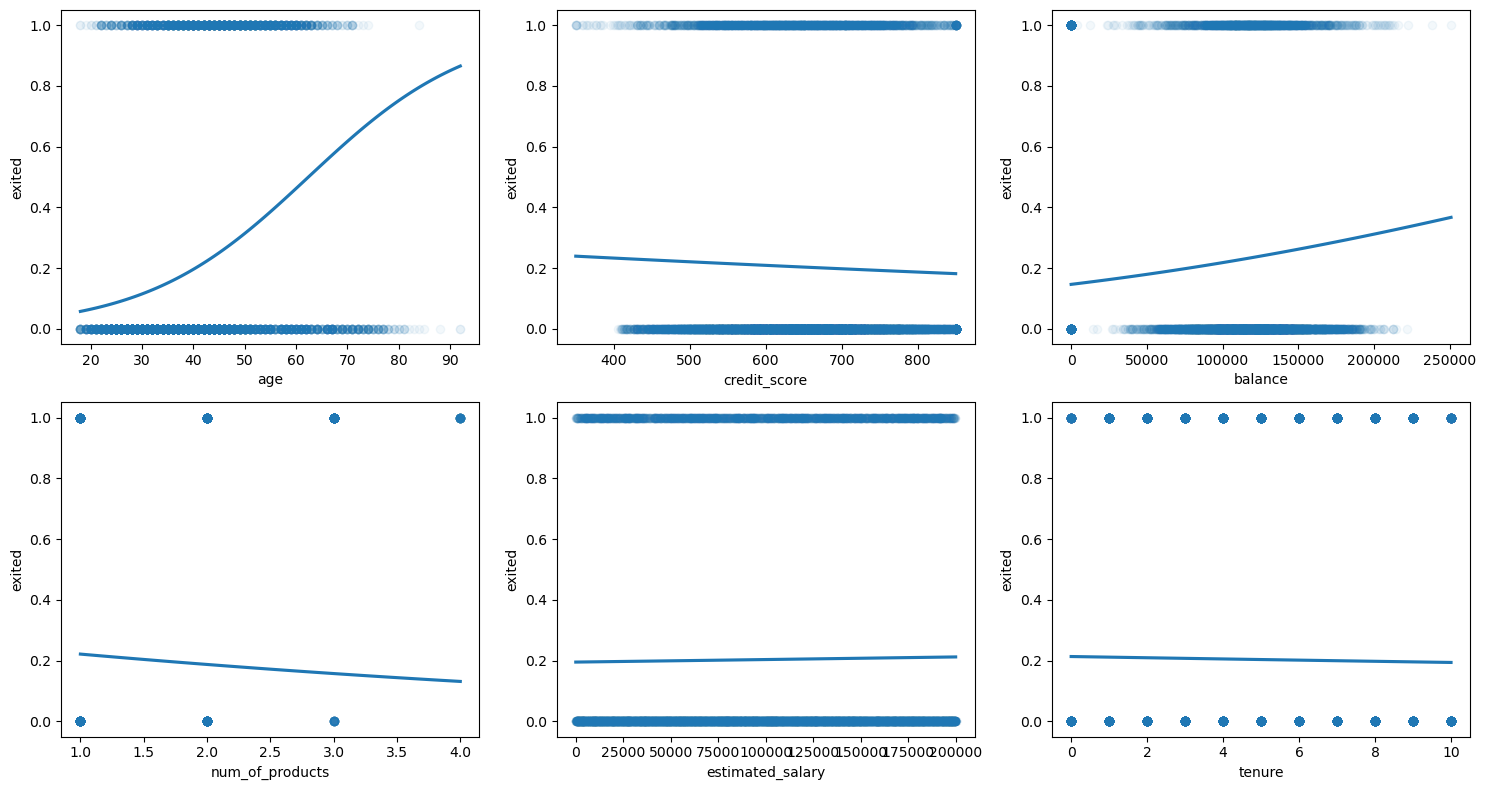

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

sns.regplot(x='age', y='exited', data=df, logistic=True, ci=None, scatter_kws={'alpha': 0.05}, ax=axes[0])
sns.regplot(x='credit_score', y='exited', data=df, logistic=True, ci=None, scatter_kws={'alpha': 0.05}, ax=axes[1])
sns.regplot(x='balance', y='exited', data=df, logistic=True, ci=None, scatter_kws={'alpha': 0.05}, ax=axes[2])
sns.regplot(x='num_of_products', y='exited', data=df, logistic=True, ci=None, scatter_kws={'alpha': 0.05}, ax=axes[3])
sns.regplot(x='estimated_salary', y='exited', data=df, logistic=True, ci=None, scatter_kws={'alpha': 0.05}, ax=axes[4])
sns.regplot(x='tenure', y='exited', data=df, logistic=True, ci=None, scatter_kws={'alpha': 0.05}, ax=axes[5])

plt.tight_layout()
plt.show()

**Exploratory Findings**

- **Age** shows a visible **nonlinear relationship** with churn; this is examined using both `age` and `age²` in the logistic regression
- **Balance** shows a **noticeable relationship** with churn, indicating a potential association between account balance and customer attrition
- The bivariate plots suggest **weaker** relationships for **credit score**, **number of products**, **estimated salary**, and **tenure**

## 3.4. Correlation Analysis

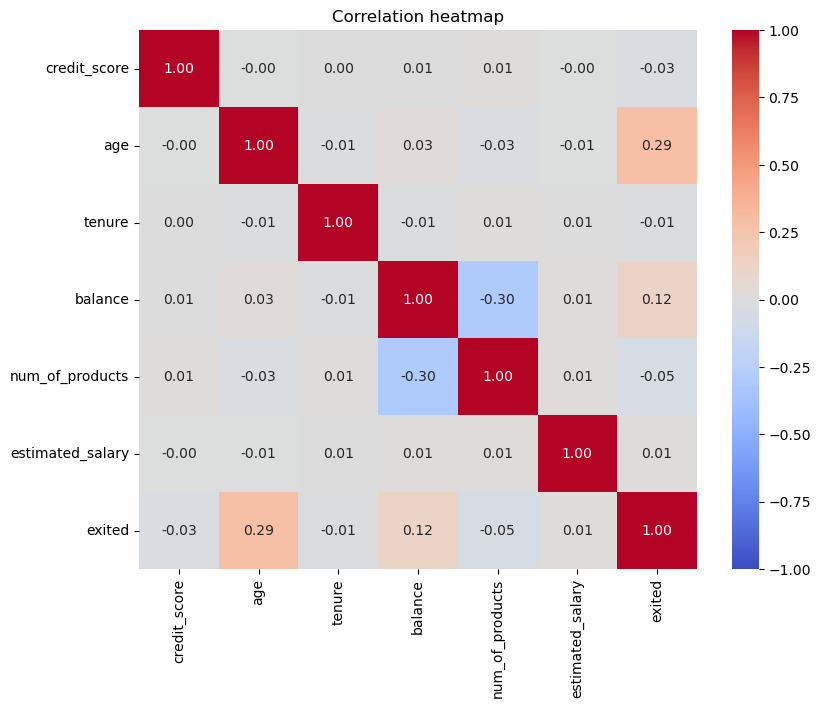

In [ ]:
num_cols = ['credit_score', 'age', 'tenure', 'balance',
            'num_of_products', 'estimated_salary', 'exited']

corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation heatmap')
plt.show()

**Correlation Findings**

- Among the numeric variables considered, **age** has the **strongest positive** linear correlation with `exited` (`r = 0.29`), followed by **balance** (`r = 0.12`)
- The remaining correlations with `exited` are **small** (`|r| ≤ 0.05`)
- Among explanatory variables, the largest notable correlation is between **balance** and **number of products** (`r ≈ -0.30`)

## 3.5. Multicollinearity (VIF)

In [ ]:
X = df[['credit_score', 'age', 'tenure', 'balance','num_of_products', 'estimated_salary']]
X = sm.add_constant(X)
vif=pd.DataFrame()
vif['variables'] = X.columns
vif['VIF'] = [variance_inflation_factor(X.values,i) for i in range(X.shape[1])]
print(vif)

          variables        VIF
0             const  77.211092
1      credit_score   1.000278
2               age   1.001493
3            tenure   1.000403
4           balance   1.102963
5   num_of_products   1.103290
6  estimated_salary   1.000638


**Multicollinearity Assessment**

- The VIF values are all below `1.2` for the six numeric predictors included in this diagnostic, suggesting **no notable multicollinearity** among those numeric predictors

# 4. Statistics - Logistic Regression


## 4.1. Logistic Regression Model ##

In [ ]:
df['products_grp'] = df['num_of_products'].clip(upper=3)
df['balance_zero'] = (df['balance']==0).astype(int)

model = smf.logit('exited ~ age + I(age**2) + credit_score + tenure + balance + estimated_salary '
                  '+ C(products_grp) + C(geography) + C(gender) + has_credit_card + is_active_member '
                  '+ balance_zero ', data = df).fit()

Optimization terminated successfully.
         Current function value: 0.360256
         Iterations 7


In [ ]:
print(model.summary())
age_peak = -model.params['age'] / (2 * model.params['I(age ** 2)'])
print(f'Churn peak age: {age_peak:.2f}')

                           Logit Regression Results                           
Dep. Variable:                 exited   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9985
Method:                           MLE   Df Model:                           14
Date:                Thu, 26 Nov 2026   Pseudo R-squ.:                  0.2873
Time:                        11:06:57   Log-Likelihood:                -3602.6
converged:                       True   LL-Null:                       -5054.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -9.4173      0.540    -17.435      0.000     -10.476      -8.359
C(products_grp)[T.2]       -1.5468      0.072    -21.340      0.000      -1.689      -1.405


**Model Fit and Statistical Findings**

- The McFadden Pseudo R² is `0.2873`. This indicates that the fitted model improves substantially over the intercept-only (null) model
- At the 5% significance level, **tenure**, **balance**, **estimated salary**, **has-credit-card status**, and **Spain** (relative to France) do not show statistically significant adjusted associations with churn
- **Age** has a statistically significant nonlinear association with churn: the coefficient of `age` is positive (`0.3493`) and the coefficient of `age²` is negative (`-0.0029`). The fitted relationship therefore rises and then falls. The turning point is calculated as `-β_age / (2β_age²)`,based on the rounded coefficients, it is approximately `59-60` years
- Holding the other included variables constant:
  - Customers using **2 products** have lower churn odds than customers using 1 product, while the **3+ product group** has substantially higher churn odds. The 3+ category combines 3 and 4 products and is small, so its estimate requires caution
  - **Germany** has higher churn odds than France, Spain does not differ significantly from France.
  - **Male customers** have lower churn odds than female customers
  - Customers with **zero balance** have higher churn odds than customers with positive balance. This differs from the raw comparison in the pairplot, where churning customers had a lower share of zero balances because that comparison does not control for the other variables, so the two results answer different questions
  - **Active members** have lower churn odds than inactive members
  - **Credit score** is borderline at the 5% thrFrance, interpret its estimated effect cautiously

## 4.2. Odds Ratio ##

In [ ]:
ci = model.conf_int()
or_table = pd.DataFrame({
    'OR': np.exp(model.params),
    '0.025': np.exp(ci[0]),
    '0.975': np.exp(ci[1]),
    'p_value': model.pvalues
}).drop(index=['Intercept', 'age', 'I(age ** 2)']).round(3)

print(or_table)

                             OR   0.025   0.975  p_value
C(products_grp)[T.2]      0.213   0.185   0.245    0.000
C(products_grp)[T.3]     17.173  11.988  24.601    0.000
C(geography)[T.Germany]   2.641   2.275   3.065    0.000
C(geography)[T.Spain]     1.037   0.892   1.205    0.639
C(gender)[T.Male]         0.591   0.526   0.665    0.000
credit_score              0.999   0.999   1.000    0.050
tenure                    0.981   0.962   1.001    0.068
balance                   1.000   1.000   1.000    0.119
estimated_salary          1.000   1.000   1.000    0.397
has_credit_card           0.947   0.834   1.076    0.402
is_active_member          0.371   0.328   0.420    0.000
balance_zero              1.484   1.080   2.039    0.015


**Odds Ratio Findings**

*Odds ratios (OR) are shown for reference. For categorical variables, they are relative to the reference group (1 product France female non-zero balance); for quantitative variables, they refer to a one-unit increase*

- Customers using **2 products** have about `0.21` times the churn odds of customers using 1 product (`95% CI: 0.185–0.245`), while customers using **3 or more products** have about `17.2` times the odds (`95% CI: 11.99–24.60`). The interval for the 3+ group is wide because the group is small
- Customers in **Germany** have about `2.64` times the churn odds of customers in France (`95% CI: 2.28–3.07`). Spain is not statistically different from France (`OR = 1.04`, `95% CI: 0.89–1.21`)
- **Male customers** have about `0.59` times the churn odds of female customers (`95% CI: 0.53–0.67`)
- **Active members** have about `0.37` times the churn odds of inactive members (`95% CI: 0.33–0.42`)
- Customers with a **zero balance** have about `1.48` times the churn odds of customers with a positive balance (`95% CI: 1.08–2.04`)
- For `tenure`, `has_credit_card`, `balance`, `estimated_salary` the `95% CI` includes 1, so there is not enough evidence of an effect at the 5% level; `credit_score` is borderline (`p ≈ 0.050`) with an odds ratio very close to 1 per unit

## 4.3. Marginal Effects ##

In [ ]:
ame = model.get_margeff(at='overall', dummy=True)
print(ame.summary())

        Logit Marginal Effects       
Dep. Variable:                 exited
Method:                          dydx
At:                           overall
                             dy/dx    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
C(products_grp)[T.2]       -0.1741      0.008    -22.955      0.000      -0.189      -0.159
C(products_grp)[T.3]        0.4446      0.030     14.947      0.000       0.386       0.503
C(geography)[T.Germany]     0.1215      0.010     11.915      0.000       0.102       0.142
C(geography)[T.Spain]       0.0041      0.009      0.467      0.640      -0.013       0.021
C(gender)[T.Male]          -0.0600      0.007     -8.761      0.000      -0.073      -0.047
age                         0.0393      0.002     17.967      0.000       0.035       0.044
I(age ** 2)                -0.0003   2.33e-05    -14.254      0.000      -0.000      -0.000
credit_score        

**Average Marginal Effects**

AME reports the average change in predicted churn probability associated with a change in a predictor, averaging across observations. For binary/categorical predictors, interpret the values as average percentage-point differences from the reference category. These are adjusted model-based associations, not causal effects.

**Categorical variables**

- Customers using **2 products** have an average predicted churn probability about `17.41` percentage points lower than customers using 1 product.
- Customers using **3 or more products** have an average predicted churn probability about `44.46` percentage points higher than customers using 1 product. This group combines 3 and 4 products and is small, so validate the group size and estimate stability.
- Customers in **Germany** have an average predicted churn probability about `12.15` percentage points higher than customers in France. Spain does not differ significantly from France (`p = 0.64`).
- **Male customers** have an average predicted churn probability about `6` percentage points lower than female customers.
- Customers with **zero balance** have an average predicted churn probability about `4.54` percentage points higher than customers with positive balance.

**Other variables**

- **Active customers** have an average predicted churn probability about `11.34` percentage points lower than inactive customers.
- A one-point increase in **credit score** is associated with an average decrease of about `0.0068` percentage points in predicted churn probability; the evidence is borderline (`p ≈ 0.050`).
- Interpret the remaining continuous-variable marginal effects in their original units. A tiny per-unit effect may accumulate over a meaningful range, but statistical significance and practical importance should be considered separately.